## FashionMNIST

In [24]:
import torch
from torch import nn

import torchvision
from torchvision import datasets
from torchvision.transforms import ToTensor
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt


In [25]:
train_data = datasets.FashionMNIST(root= 'data',
                                   train= True,
                                   transform= ToTensor(),
                                   download= True,
                                   target_transform= None)


test_data = datasets.FashionMNIST(root= 'data',
                                  train= False,
                                  transform= ToTensor(),
                                  download= True,
                                  target_transform= None)

In [26]:
train_data

Dataset FashionMNIST
    Number of datapoints: 60000
    Root location: data
    Split: Train
    StandardTransform
Transform: ToTensor()

In [27]:
test_data

Dataset FashionMNIST
    Number of datapoints: 10000
    Root location: data
    Split: Test
    StandardTransform
Transform: ToTensor()

In [28]:
image, label = train_data[0]
image, label

(tensor([[[0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0039, 0.0000, 0.0000, 0.0510,
           0.2863, 0.0000, 0.0000, 0.0039, 

In [29]:
image.shape # 1 gray colors, 28*28 height and width

torch.Size([1, 28, 28])

In [30]:
len(train_data.data), len(train_data.targets), len(test_data.data), len(test_data.targets)

(60000, 60000, 10000, 10000)

In [31]:
class_names = train_data.classes
class_names

['T-shirt/top',
 'Trouser',
 'Pullover',
 'Dress',
 'Coat',
 'Sandal',
 'Shirt',
 'Sneaker',
 'Bag',
 'Ankle boot']

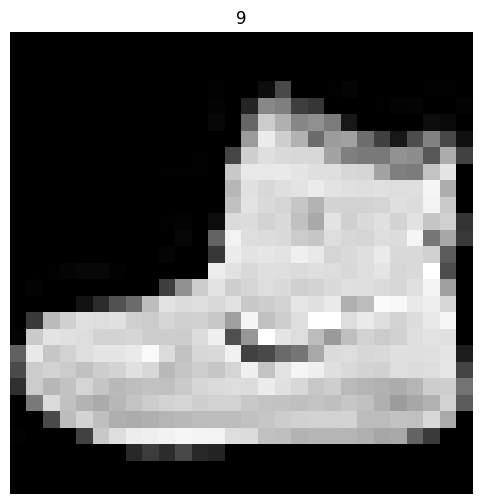

In [32]:
plt.figure(figsize=(12,6))
plt.imshow(image.squeeze(), cmap= "gray")
plt.title(label)
plt.axis('off')
plt.show()

In [33]:
train_data_loader = DataLoader(train_data,
                                batch_size= 32,
                                shuffle= True,
                               )

test_data_loader = DataLoader(test_data,
                                batch_size= 32,
                                shuffle= False)

In [34]:
len(train_data_loader), len(test_data_loader)

(1875, 313)

In [35]:
next(iter(train_data_loader))

[tensor([[[[0., 0., 0.,  ..., 0., 0., 0.],
           [0., 0., 0.,  ..., 0., 0., 0.],
           [0., 0., 0.,  ..., 0., 0., 0.],
           ...,
           [0., 0., 0.,  ..., 0., 0., 0.],
           [0., 0., 0.,  ..., 0., 0., 0.],
           [0., 0., 0.,  ..., 0., 0., 0.]]],
 
 
         [[[0., 0., 0.,  ..., 0., 0., 0.],
           [0., 0., 0.,  ..., 0., 0., 0.],
           [0., 0., 0.,  ..., 0., 0., 0.],
           ...,
           [0., 0., 0.,  ..., 0., 0., 0.],
           [0., 0., 0.,  ..., 0., 0., 0.],
           [0., 0., 0.,  ..., 0., 0., 0.]]],
 
 
         [[[0., 0., 0.,  ..., 0., 0., 0.],
           [0., 0., 0.,  ..., 0., 0., 0.],
           [0., 0., 0.,  ..., 0., 0., 0.],
           ...,
           [0., 0., 0.,  ..., 0., 0., 0.],
           [0., 0., 0.,  ..., 0., 0., 0.],
           [0., 0., 0.,  ..., 0., 0., 0.]]],
 
 
         ...,
 
 
         [[[0., 0., 0.,  ..., 0., 0., 0.],
           [0., 0., 0.,  ..., 0., 0., 0.],
           [0., 0., 0.,  ..., 0., 0., 0.],
           ..

In [36]:
# Create a convolutional neural network 
class FashionMNISTModelV2(nn.Module):
    def __init__(self, input_shape: int, hidden_units: int, output_shape: int):
        super().__init__()
        
        self.block1 = nn.Sequential(
            nn.Conv2d(in_channels= input_shape, out_channels= hidden_units, kernel_size= 3, stride= 1, padding= 1),
            nn.ReLU(),
            nn.Conv2d(in_channels= hidden_units, out_channels= hidden_units, kernel_size= 3, stride= 1, padding= 1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size= 2, stride= 2)
        )
        
        self.block2 = nn.Sequential(
            nn.Conv2d(in_channels= hidden_units, out_channels= hidden_units, kernel_size= 3, stride= 1, padding= 1),
            nn.ReLU(),
            nn.Conv2d(in_channels= hidden_units, out_channels= output_shape, kernel_size= 3, stride= 1, padding= 1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size= 2, stride= 2)
        )
        
        self.classifier = nn.Sequential(
                nn.Flatten(),
                nn.Linear(in_features= hidden_units*7*7, out_features= output_shape)
        )
        
        
    def forward(self, x):
        return self.classifier(self.block2(self.block1(x)))

In [37]:
torch.manual_seed(42)
model = FashionMNISTModelV2(input_shape=1,  hidden_units=10, output_shape=len(class_names))

model

FashionMNISTModelV2(
  (block1): Sequential(
    (0): Conv2d(1, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (block2): Sequential(
    (0): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=490, out_features=10, bias=True)
  )
)

In [38]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(params= model.parameters(), lr= 0.1)

In [39]:
def accuracy_fn(y_true, y_pred):
    correct = torch.eq(y_true, y_pred).sum().item()
    acc = (correct / len(y_pred)) * 100
    return acc

In [ ]:
# create a training function

def train_step(model: torch.nn.Module,
               data_loader: torch.utils.data.DataLoader,
               loss_fn: torch.nn.Module,
               optimizer: torch.optim.Optimizer,
               accuracy_fn):
    
    train_loss, train_acc = 0, 0
    
    for batch, (X,y) in enumerate(data_loader):
        y_pred = model(X)
        loss = loss_fn(y_pred, y)
        
        train_loss+= loss
        train_acc+= accuracy_fn(y, y_pred.argmax(dim=1))
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        
    train_loss/= len(data_loader)
    train_acc/= len(data_loader)
    print(f"Train loss : {train_loss:.5f} | Train accuracy : {train_acc:.2f}%")
        
        
        
        
        

def test_step(model: torch.nn.Module,
              data_loader: torch.utils.data.DataLoader,
              loss_fn: torch.nn.Module,
              accuracy_fn):
    
    test_acc, test_loss = 0,0
    model.eval()
    with torch.inference_mode():
        for X,y in data_loader:
            test_pred = model(X)
            
            test_loss+= loss_fn(test_pred, y)
            test_acc+= accuracy_fn(y, test_pred.argmax(dim=1))
            
        test_loss/= len(data_loader)
        test_acc/= len(data_loader)
        print(f"Test loss: {test_loss:.5f} | Test accuracy: {test_acc:.2f}%\n")
        

In [41]:
torch.manual_seed(42)
epochs = 3

for epoch in range(epochs):
    print(f"Epoch : {epoch}\n-------------------")
    train_step(model, train_data_loader, loss_fn, optimizer, accuracy_fn)
    test_step(model, test_data_loader, loss_fn, accuracy_fn)
    
    

Epoch : 0
-------------------
Train loss : 0.58824 | Train accuracy : 78.64%
Test loss: 0.38307 | Test accuracy: 86.43%

Epoch : 1
-------------------
Train loss : 0.36087 | Train accuracy : 87.00%
Test loss: 0.35129 | Test accuracy: 87.03%

Epoch : 2
-------------------
Train loss : 0.32311 | Train accuracy : 88.31%
Test loss: 0.31496 | Test accuracy: 88.21%



In [51]:
def eval_model(model: torch.nn.Module, 
               data_loader: torch.utils.data.DataLoader,
               loss_fn: torch.nn.Module,
               accuracy_fn):
    
    loss, acc = 0, 0
    model.eval()
    with torch.inference_mode():
        for X, y in data_loader:
            y_pred = model(X)
            
            loss+= loss_fn(y_pred, y)
            acc+= accuracy_fn(y, y_pred.argmax(dim=1))
            
        loss/= len(data_loader)
        acc/= len(data_loader)
        print(f"Model name : {model.__class__.__name__} | Loss : {loss} | Accuracy : {acc}")
        
       
eval_model(model, test_data_loader, loss_fn, accuracy_fn)

Model name : FashionMNISTModelV2 | Loss : 0.31495797634124756 | Accuracy : 88.20886581469648


In [52]:

y_preds = []
model.eval()
with torch.inference_mode():
  for X, y in test_data_loader:
    y_logit = model(X)
    y_pred = torch.softmax(y_logit, dim=1).argmax(dim=1) 
    
    y_preds.append(y_pred)
y_pred_tensor = torch.cat(y_preds)

In [55]:
"""from torchmetrics import ConfusionMatrix
from mlxtend.plotting import plot_confusion_matrix

confmat = ConfusionMatrix('multiclass', num_classes= len(class_names))

confmat_tensor = confmat(preds=y_pred_tensor,
                         target=test_data.targets)

fig, ax = plot_confusion_matrix(confmat_tensor.numpy(), class_names= class_names, figsize=(10,7))
"""

"from torchmetrics import ConfusionMatrix\nfrom mlxtend.plotting import plot_confusion_matrix\n\nconfmat = ConfusionMatrix('multiclass', num_classes= len(class_names))\n\nconfmat_tensor = confmat(preds=y_pred_tensor,\n                         target=test_data.targets)\n\nfig, ax = plot_confusion_matrix(confmat_tensor.numpy(), class_names= class_names, figsize=(10,7))\n"

## MNIST

In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

import torch
from torch import nn
from torch.utils.data import DataLoader

import torchvision
from torchvision.datasets import MNIST
from torchvision.transforms import ToTensor

from torchmetrics import Accuracy, ConfusionMatrix



In [14]:
# 1- Load the mnist dataset

train_data = MNIST(root= 'mnist_data',
                    train= True,
                    transform= ToTensor(),
                    download= True,
                    target_transform= None)

test_data = MNIST(root= 'mnist_data',
                    train= False,
                    transform= ToTensor(),
                    download= True)

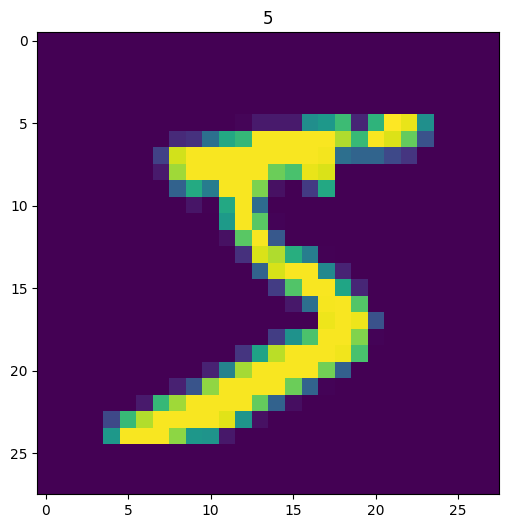

In [15]:
# plot one image
image, label = train_data[0]


plt.figure(figsize=(12, 6))
plt.imshow(image.squeeze())
plt.title(label)
plt.show()

In [12]:
class_names = train_data.classes
class_names

['0 - zero',
 '1 - one',
 '2 - two',
 '3 - three',
 '4 - four',
 '5 - five',
 '6 - six',
 '7 - seven',
 '8 - eight',
 '9 - nine']

In [16]:
# 2- load data using data loader

train_data_loader = DataLoader(train_data,
                                batch_size= 32,
                                shuffle= True
                                )

test_data_loader = DataLoader(test_data,
                                batch_size= 32,
                                shuffle= False
                                )

In [17]:
image.shape

torch.Size([1, 28, 28])

In [22]:
# 3- Build Mnist Model
class MNISTModel(nn.Module):
    def __init__(self, input_shape: int, hidden_units: int, output_shape: int ):
        super().__init__()
        
        self.block1 = nn.Sequential(
            nn.Conv2d(in_channels= input_shape, out_channels= hidden_units, kernel_size= 3, stride= 1, padding= 1),
            nn.ReLU(),
            nn.Conv2d(in_channels= hidden_units, out_channels= hidden_units, kernel_size= 3, stride= 1, padding= 1 ),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size= 2)
        )
        
        
        self.block2 = nn.Sequential(
            nn.Conv2d(in_channels= hidden_units, out_channels= hidden_units, kernel_size= 3, stride= 1, padding= 1),
            nn.ReLU(),
            nn.Conv2d(in_channels= hidden_units, out_channels= hidden_units, kernel_size= 3, stride= 1, padding= 1 ),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size= 2)
        )
        
        self.classifier = nn.Sequential(
                nn.Flatten(),
                nn.Linear(in_features= hidden_units*7*7, out_features= output_shape)
        )
        
    def forward(self, x):
        return self.classifier(self.block2(self.block1(x)))
    
    

In [ ]:
# 4- Initialize the model

mnistModel = MNISTModel(input_shape= 1, hidden_units= 10, output_shape= len(class_names))
mnistModel

MNISTModel(
  (block1): Sequential(
    (0): Conv2d(1, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (block2): Sequential(
    (0): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=490, out_features=10, bias=True)
  )
)

In [24]:
# 5- Initialize loss and optimizer
loss_fn = nn.CrossEntropyLoss() # ---> multiclass classification problem
optimizer = torch.optim.SGD(params= mnistModel.parameters(), lr= 0.1)

In [ ]:
# define accuracy
accuracy_fn = Accuracy(task="multiclass", num_classes=len(class_names))

In [ ]:
# 6- Train and Test function

def train_step(model: torch.nn.Module,
                dataloader: torch.utils.data.DataLoader,
                loss_fn: torch.nn.Module,
                optimizer: torch.optim,
                accuracy_fn: Accuracy
                ):
    train_acc, train_loss = 0, 0
    model.train()
    
    for batch, (X, y) in enumerate(dataloader):
        y_pred = model(X)
        loss = loss_fn(y_pred, y)
        acc = accuracy_fn(y_pred.argmax(dim=1), y)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        
        train_acc+= acc
        train_loss+= loss
        
    # Calculer la moyenne de loss et accuracy de chaque batch
    train_acc/= len(dataloader)
    train_loss/= len(dataloader)
    
    print(f"Train Loss : {train_loss:.5f} | Train accuracy : {train_acc:.2f}%")
    
    
    
# --------------------------------------------------------------------------------------------


    
def test_step(model: torch.nn.Module,
                dataloader: torch.utils.data.DataLoader,
                loss_fn: torch.nn.Module,
                accuracy_fn: Accuracy
                ):
    
    model.eval()
    test_acc, test_loss = 0, 0
    
    with torch.inference_mode():
        for X, y in dataloader:
            test_pred = model(X)
            loss = loss_fn(test_pred, y)
            acc = accuracy_fn(test_pred.argmax(dim=1), y)
            
            test_acc+= acc
            test_loss+= loss
        
        # calculate the average of test loss and test accuracy for each batch
        test_acc/= len(dataloader)
        test_loss/= len(dataloader)
        
        print(f"Test Loss : {test_loss:.5f} | Test accuracy {test_acc:.2f}%")

In [48]:
# 7)- Train the model

torch.manual_seed(42)
epochs = 4

for epoch in range(epochs):
    print(f"Epoch :  {epoch} --------------------------------------------------")
    train_step(model= mnistModel, 
                dataloader= train_data_loader, 
                loss_fn= loss_fn, 
                optimizer= optimizer, 
                accuracy_fn= accuracy_fn)
    
    
    test_step(model= mnistModel, 
                dataloader= test_data_loader, 
                loss_fn= loss_fn, 
                accuracy_fn= accuracy_fn)

Epoch :  0 --------------------------------------------------
Train Loss : 0.35576 
Test Loss : 0.07821 
Epoch :  1 --------------------------------------------------
Train Loss : 0.07793 
Test Loss : 0.05601 
Epoch :  2 --------------------------------------------------
Train Loss : 0.06101 
Test Loss : 0.05430 
Epoch :  3 --------------------------------------------------
Train Loss : 0.05220 
Test Loss : 0.04815 


In [54]:
# Make predictions

mnistModel.eval()
loss, acc = 0 ,0
with torch.inference_mode():
    for X, y in test_data_loader:
        predictions = mnistModel(X)
        loss = loss_fn(predictions, y)
        acc = accuracy_fn(predictions.argmax(dim=1), y)
        
        loss+= loss
        acc+= acc
    
    loss/= len(test_data_loader)
    acc/= len(test_data_loader)
    
    print(f"Accuracy : {acc:.2f}% | Loss : {loss:.5f}")

Accuracy : 0.01% | Loss : 0.00002
